# JJA

In [22]:
# Land only

import xarray as xr
import numpy as np
import pandas as pd
import regionmask

# ── File paths ────────────────────────────────────────────────────────────────
pr_file   = "/Users/dianindrawati/Documents/CMIP6_datasets/CMCC-CM2-SR5/pr/CMCC-CM2-SR5_pr_future126_20712100_seasonal.nc"
hfls_file = "/Users/dianindrawati/Documents/CMIP6_datasets/CMCC-CM2-SR5/hfls/CMCC-CM2-SR5_hfls_future126_20712100_seasonal.nc"

PERIOD_LABEL   = "2071_2100"
MODEL_LABEL    = "CMCC-CM2-SR5"      # FIX: was mislabeled "NorESM2-LM" while loading NorESM2-MM files
SCENARIO_LABEL = "SSP126"
output_dir     = "/Users/dianindrawati/Documents/Python/CMIP6_and_ERA5/P_over_E"

# ── Load ──────────────────────────────────────────────────────────────────────
ds_pr   = xr.open_dataset(pr_file,   use_cftime=True)
ds_hfls = xr.open_dataset(hfls_file, use_cftime=True)

# ── Align on time (pr/hfls files can have mismatched time axes, e.g. leap days) ──
ds_pr, ds_hfls = xr.align(ds_pr, ds_hfls, join='inner', exclude=[])

# Guard against descending latitude grids, which would silently make
# lat_min/lat_max slices return empty arrays further down.
if ds_pr['lat'].values[0] > ds_pr['lat'].values[-1]:
    ds_pr = ds_pr.sortby('lat')
if ds_hfls['lat'].values[0] > ds_hfls['lat'].values[-1]:
    ds_hfls = ds_hfls.sortby('lat')

pr   = ds_pr['pr']
hfls = ds_hfls['hfls']

# ── Land-only mask (Natural Earth 110m land polygons, via regionmask) ─────────
# Consistent with the land-masking approach used in the other CMIP6 warming
# analysis (regionmask rather than model-native sftlf).
land_110 = regionmask.defined_regions.natural_earth_v5_0_0.land_110
land_mask_2d = land_110.mask(ds_pr['lon'], ds_pr['lat'])   # NaN over ocean, 0 over land
land_mask_bool = land_mask_2d.notnull()                    # True over land, False over ocean

# ── Unit conversions (both → mm/day) ─────────────────────────────────────────
pr_mm_day = pr * 86400
L_v, rho_w = 2.5e6, 1000
e_mm_day   = (hfls / (L_v * rho_w)) * 86400 * 1000

# ── Select JJA months ─────────────────────────────────────────────────────────
mask_jja = pr_mm_day['time'].dt.month.isin([6, 7, 8])
pr_jja   = pr_mm_day.sel(time=mask_jja)
e_jja    = e_mm_day.sel(time=mask_jja)

# ── Aggregate P and E separately into JJA climatological mean ─────────────────
pr_jja_mean = pr_jja.groupby('time.year').mean('time').mean('year')   # per-cell climatological mean P (mm/day)
e_jja_mean  = e_jja.groupby('time.year').mean('time').mean('year')    # per-cell climatological mean E (mm/day)

# ── Apply land mask to both fields before regional aggregation ───────────────
pr_jja_mean = pr_jja_mean.where(land_mask_bool)
e_jja_mean  = e_jja_mean.where(land_mask_bool)

# ── Area weights ──────────────────────────────────────────────────────────────
lat = ds_pr['lat'].values
lon = ds_pr['lon'].values
weights_2d = np.broadcast_to(
    np.cos(np.deg2rad(lat))[:, np.newaxis], (len(lat), len(lon))
)
weights_da = xr.DataArray(weights_2d, dims=['lat', 'lon'],
                           coords={'lat': lat, 'lon': lon})

# ── Region definitions ────────────────────────────────────────────────────────
lat_bins     = [(-60, -35), (-35, -23.5), (-23.5, 23.5), (23.5, 35), (35, 60)]
region_names = ['R01_SM', 'R02_SS', 'R03_Tropics', 'R04_NS', 'R05_NM']

# ── Region E/P via ratio-of-sums, land only ───────────────────────────────────
# Rather than averaging per-cell E/P ratios (unstable where P→0), we sum the
# area-weighted E and P fields separately over the region's land cells first,
# then take the ratio of those two regional land totals. This is the standard
# water-balance way to report a regional E/P and avoids small-denominator
# blowups from individual dry cells. Ocean cells are excluded via
# land_mask_bool above, so both sums here are over land only.
results = []
for region_name, (lat_min, lat_max) in zip(region_names, lat_bins):
    pr_region = pr_jja_mean.sel(lat=slice(lat_min, lat_max))
    e_region  = e_jja_mean.sel(lat=slice(lat_min, lat_max))
    w_region  = weights_da.sel(lat=slice(lat_min, lat_max))

    # valid where both P and E are finite AND cell is land
    valid_mask = np.isfinite(pr_region) & np.isfinite(e_region)

    pr_weighted_sum = (pr_region * w_region).where(valid_mask).sum()
    e_weighted_sum  = (e_region  * w_region).where(valid_mask).sum()

    region_e_over_p = float((e_weighted_sum / pr_weighted_sum).values)

    results.append({
        'Region':   region_name,
        'E_over_P': region_e_over_p
    })

# ── Save ──────────────────────────────────────────────────────────────────────
df = pd.DataFrame(results)
out_csv = f"{output_dir}/mean_E_over_P_ratioSum_landmasked_{PERIOD_LABEL}_{MODEL_LABEL}_{SCENARIO_LABEL}_JJA.csv"
df.to_csv(out_csv, index=False)

print(f"Saved → {out_csv}")
print(f"\n{df.to_string(index=False)}")

ds_pr.close()
ds_hfls.close()

Saved → /Users/dianindrawati/Documents/Python/CMIP6_and_ERA5/P_over_E/mean_E_over_P_ratioSum_landmasked_2071_2100_CMCC-CM2-SR5_SSP126_JJA.csv

     Region  E_over_P
     R01_SM  0.359623
     R02_SS  1.282449
R03_Tropics  0.702576
     R04_NS  0.536874
     R05_NM  1.047081


In [1]:
import xarray as xr
import numpy as np
import pandas as pd

# ── File paths ────────────────────────────────────────────────────────────────
pr_file   = "/Users/dianindrawati/Documents/CMIP6_datasets/NorESM2-MM/pr/NorESM2-MM_pr_future126_20212050_seasonal.nc"
hfls_file = "/Users/dianindrawati/Documents/CMIP6_datasets/NorESM2-MM/hfls/NorESM2-MM_hfls_future126_20212050_seasonal.nc"

PERIOD_LABEL   = "2021_2050"
MODEL_LABEL    = "NorESM2-LM"
SCENARIO_LABEL = "SSP126"
output_dir     = "/Users/dianindrawati/Documents/Python/CMIP6_and_ERA5/P_over_E"

# ── Load ──────────────────────────────────────────────────────────────────────
ds_pr   = xr.open_dataset(pr_file,   use_cftime=True)
ds_hfls = xr.open_dataset(hfls_file, use_cftime=True)

# ── Align on time (pr/hfls files can have mismatched time axes, e.g. leap days) ──
ds_pr, ds_hfls = xr.align(ds_pr, ds_hfls, join='inner', exclude=[])

pr   = ds_pr['pr']
hfls = ds_hfls['hfls']

# ── Unit conversions (both → mm/day) ─────────────────────────────────────────
pr_mm_day = pr * 86400
L_v, rho_w = 2.5e6, 1000
e_mm_day   = (hfls / (L_v * rho_w)) * 86400 * 1000

# ── Select JJA months ─────────────────────────────────────────────────────────
mask_jja = pr_mm_day['time'].dt.month.isin([6, 7, 8])
pr_jja   = pr_mm_day.sel(time=mask_jja)
e_jja    = e_mm_day.sel(time=mask_jja)

# ── Aggregate P and E separately into JJA climatological mean ─────────────────
pr_jja_mean = pr_jja.groupby('time.year').mean('time').mean('year')   # per-cell climatological mean P (mm/day)
e_jja_mean  = e_jja.groupby('time.year').mean('time').mean('year')    # per-cell climatological mean E (mm/day)

# ── Area weights ──────────────────────────────────────────────────────────────
lat = ds_pr['lat'].values
lon = ds_pr['lon'].values
weights_2d = np.broadcast_to(
    np.cos(np.deg2rad(lat))[:, np.newaxis], (len(lat), len(lon))
)
weights_da = xr.DataArray(weights_2d, dims=['lat', 'lon'],
                           coords={'lat': lat, 'lon': lon})

# ── Region definitions ────────────────────────────────────────────────────────
lat_bins     = [(-60, -35), (-35, -23.5), (-23.5, 23.5), (23.5, 35), (35, 60)]
region_names = ['R01_SM', 'R02_SS', 'R03_Tropics', 'R04_NS', 'R05_NM']

# ── Region E/P via ratio-of-sums ──────────────────────────────────────────────
# Rather than averaging per-cell E/P ratios (unstable where P→0), we sum the
# area-weighted E and P fields separately over the region first, then take
# the ratio of those two regional totals. This is the standard water-balance
# way to report a regional E/P and avoids small-denominator blowups from
# individual dry cells.
results = []
for region_name, (lat_min, lat_max) in zip(region_names, lat_bins):
    pr_region = pr_jja_mean.sel(lat=slice(lat_min, lat_max))
    e_region  = e_jja_mean.sel(lat=slice(lat_min, lat_max))
    w_region  = weights_da.sel(lat=slice(lat_min, lat_max))

    # valid where both P and E are finite (NaN land/ocean mask, missing data, etc.)
    valid_mask = np.isfinite(pr_region) & np.isfinite(e_region)

    pr_weighted_sum = (pr_region * w_region).where(valid_mask).sum()
    e_weighted_sum  = (e_region  * w_region).where(valid_mask).sum()

    region_e_over_p = float((e_weighted_sum / pr_weighted_sum).values)

    results.append({
        'Region':   region_name,
        'E_over_P': region_e_over_p
    })

# ── Save ──────────────────────────────────────────────────────────────────────
df = pd.DataFrame(results)
out_csv = f"{output_dir}/mean_E_over_P_ratioSum_{PERIOD_LABEL}_{MODEL_LABEL}_{SCENARIO_LABEL}_JJA.csv"
df.to_csv(out_csv, index=False)

print(f"Saved → {out_csv}")
print(f"\n{df.to_string(index=False)}")

ds_pr.close()
ds_hfls.close()

Saved → /Users/dianindrawati/Documents/Python/CMIP6_and_ERA5/P_over_E/mean_E_over_P_ratioSum_2021_2050_NorESM2-LM_SSP126_JJA.csv

     Region  E_over_P
     R01_SM  0.782313
     R02_SS  1.687966
R03_Tropics  1.119774
     R04_NS  1.064063
     R05_NM  0.776820


# DJF

In [44]:
# Land only

import xarray as xr
import numpy as np
import pandas as pd
import regionmask

# ── File paths ────────────────────────────────────────────────────────────────
pr_file   = "/Users/dianindrawati/Documents/CMIP6_datasets/CMCC-CM2-SR5/pr/CMCC-CM2-SR5_pr_future126_20712100_seasonal.nc"
hfls_file = "/Users/dianindrawati/Documents/CMIP6_datasets/CMCC-CM2-SR5/hfls/CMCC-CM2-SR5_hfls_future126_20712100_seasonal.nc"

PERIOD_LABEL   = "2071_2100"
MODEL_LABEL    = "CMCC-CM2-SR5"      # FIX: was mislabeled "NorESM2-LM" while loading NorESM2-MM files
SCENARIO_LABEL = "SSP126"
output_dir     = "/Users/dianindrawati/Documents/Python/CMIP6_and_ERA5/P_over_E"

# ── Load ──────────────────────────────────────────────────────────────────────
ds_pr   = xr.open_dataset(pr_file,   use_cftime=True)
ds_hfls = xr.open_dataset(hfls_file, use_cftime=True)

# ── Align on time (pr/hfls files can have mismatched time axes, e.g. leap days) ──
ds_pr, ds_hfls = xr.align(ds_pr, ds_hfls, join='inner', exclude=[])

# Guard against descending latitude grids, which would silently make
# lat_min/lat_max slices return empty arrays further down.
if ds_pr['lat'].values[0] > ds_pr['lat'].values[-1]:
    ds_pr = ds_pr.sortby('lat')
if ds_hfls['lat'].values[0] > ds_hfls['lat'].values[-1]:
    ds_hfls = ds_hfls.sortby('lat')

pr   = ds_pr['pr']
hfls = ds_hfls['hfls']

# ── Land-only mask (Natural Earth 110m land polygons, via regionmask) ─────────
# Consistent with the land-masking approach used in the other CMIP6 warming
# analysis (regionmask rather than model-native sftlf).
land_110 = regionmask.defined_regions.natural_earth_v5_0_0.land_110
land_mask_2d = land_110.mask(ds_pr['lon'], ds_pr['lat'])   # NaN over ocean, 0 over land
land_mask_bool = land_mask_2d.notnull()                    # True over land, False over ocean

# ── Unit conversions (both → mm/day) ─────────────────────────────────────────
pr_mm_day = pr * 86400
L_v, rho_w = 2.5e6, 1000
e_mm_day   = (hfls / (L_v * rho_w)) * 86400 * 1000

# ── Assign DJF season_year: Dec → year+1, so Dec(Y) + Jan(Y+1) + Feb(Y+1) ───
def assign_season_year(da):
    months      = da['time'].dt.month.values
    years       = da['time'].dt.year.values
    season_year = np.where(months == 12, years + 1, years)
    return da.assign_coords(season_year=('time', season_year))

pr_tagged = assign_season_year(pr_mm_day)
e_tagged  = assign_season_year(e_mm_day)

# ── Select DJF months ─────────────────────────────────────────────────────────
mask_djf = pr_tagged['time'].dt.month.isin([12, 1, 2])
pr_djf   = pr_tagged.sel(time=mask_djf)
e_djf    = e_tagged.sel(time=mask_djf)

# ── Aggregate P and E separately into DJF seasonal means ─────────────────────
pr_djf_yr = pr_djf.groupby('season_year').mean('time')
e_djf_yr  = e_djf.groupby('season_year').mean('time')

# Drop boundary seasons (first may lack Dec, last may lack Jan+Feb)
sy_vals   = pr_djf_yr['season_year'].values
pr_djf_yr = pr_djf_yr.sel(season_year=sy_vals[1:-1])
e_djf_yr  = e_djf_yr.sel(season_year=sy_vals[1:-1])

pr_djf_mean = pr_djf_yr.mean('season_year')   # per-cell climatological mean P (mm/day)
e_djf_mean  = e_djf_yr.mean('season_year')    # per-cell climatological mean E (mm/day)

# ── Apply land mask to both fields before regional aggregation ───────────────
pr_djf_mean = pr_djf_mean.where(land_mask_bool)
e_djf_mean  = e_djf_mean.where(land_mask_bool)

# ── Area weights ──────────────────────────────────────────────────────────────
lat = ds_pr['lat'].values
lon = ds_pr['lon'].values
weights_2d = np.broadcast_to(
    np.cos(np.deg2rad(lat))[:, np.newaxis], (len(lat), len(lon))
)
weights_da = xr.DataArray(weights_2d, dims=['lat', 'lon'],
                           coords={'lat': lat, 'lon': lon})

# ── Region definitions ────────────────────────────────────────────────────────
lat_bins     = [(-60, -35), (-35, -23.5), (-23.5, 23.5), (23.5, 35), (35, 60)]
region_names = ['R01_SM', 'R02_SS', 'R03_Tropics', 'R04_NS', 'R05_NM']

# ── Region E/P via ratio-of-sums, land only ───────────────────────────────────
# Rather than averaging per-cell E/P ratios (unstable where P→0), we sum the
# area-weighted E and P fields separately over the region's land cells first,
# then take the ratio of those two regional land totals. This is the standard
# water-balance way to report a regional E/P and avoids small-denominator
# blowups from individual dry cells. Ocean cells are excluded via
# land_mask_bool above, so both sums here are over land only.
results = []
for region_name, (lat_min, lat_max) in zip(region_names, lat_bins):
    pr_region = pr_djf_mean.sel(lat=slice(lat_min, lat_max))
    e_region  = e_djf_mean.sel(lat=slice(lat_min, lat_max))
    w_region  = weights_da.sel(lat=slice(lat_min, lat_max))

    # valid where both P and E are finite AND cell is land
    valid_mask = np.isfinite(pr_region) & np.isfinite(e_region)

    pr_weighted_sum = (pr_region * w_region).where(valid_mask).sum()
    e_weighted_sum  = (e_region  * w_region).where(valid_mask).sum()

    region_e_over_p = float((e_weighted_sum / pr_weighted_sum).values)

    results.append({
        'Region':   region_name,
        'E_over_P': region_e_over_p
    })

# ── Save ──────────────────────────────────────────────────────────────────────
df = pd.DataFrame(results)
out_csv = f"{output_dir}/mean_E_over_P_ratioSum_landmasked_{PERIOD_LABEL}_{MODEL_LABEL}_{SCENARIO_LABEL}_DJF.csv"
df.to_csv(out_csv, index=False)

print(f"Saved → {out_csv}")
print(f"\n{df.to_string(index=False)}")

ds_pr.close()
ds_hfls.close()

Saved → /Users/dianindrawati/Documents/Python/CMIP6_and_ERA5/P_over_E/mean_E_over_P_ratioSum_landmasked_2071_2100_CMCC-CM2-SR5_SSP126_DJF.csv

     Region  E_over_P
     R01_SM  0.886133
     R02_SS  0.780479
R03_Tropics  0.578844
     R04_NS  0.888102
     R05_NM  0.286560


In [24]:
import xarray as xr
import numpy as np
import pandas as pd

# ── File paths ────────────────────────────────────────────────────────────────
pr_file   = "/Users/dianindrawati/Documents/CMIP6_datasets/NorESM2-MM/pr/NorESM2-MM_pr_future126_20212050_seasonal.nc"
hfls_file = "/Users/dianindrawati/Documents/CMIP6_datasets/NorESM2-MM/hfls/NorESM2-MM_hfls_future126_20212050_seasonal.nc"

PERIOD_LABEL   = "2021_2050"
MODEL_LABEL    = "NorESM2-LM"
SCENARIO_LABEL = "SSP126"
output_dir     = "/Users/dianindrawati/Documents/Python/CMIP6_and_ERA5/P_over_E"

# ── Load ──────────────────────────────────────────────────────────────────────
ds_pr   = xr.open_dataset(pr_file,   use_cftime=True)
ds_hfls = xr.open_dataset(hfls_file, use_cftime=True)

# ── Align on time (pr/hfls files can have mismatched time axes, e.g. leap days) ──
ds_pr, ds_hfls = xr.align(ds_pr, ds_hfls, join='inner', exclude=[])

pr   = ds_pr['pr']
hfls = ds_hfls['hfls']

# ── Unit conversions (both → mm/day) ─────────────────────────────────────────
pr_mm_day = pr * 86400
L_v, rho_w = 2.5e6, 1000
e_mm_day   = (hfls / (L_v * rho_w)) * 86400 * 1000

# ── Assign DJF season_year: Dec → year+1, so Dec(Y) + Jan(Y+1) + Feb(Y+1) ───
def assign_season_year(da):
    months      = da['time'].dt.month.values
    years       = da['time'].dt.year.values
    season_year = np.where(months == 12, years + 1, years)
    return da.assign_coords(season_year=('time', season_year))

pr_tagged = assign_season_year(pr_mm_day)
e_tagged  = assign_season_year(e_mm_day)

# ── Select DJF months ─────────────────────────────────────────────────────────
mask_djf = pr_tagged['time'].dt.month.isin([12, 1, 2])
pr_djf   = pr_tagged.sel(time=mask_djf)
e_djf    = e_tagged.sel(time=mask_djf)

# ── Aggregate P and E separately into DJF seasonal means ─────────────────────
pr_djf_yr = pr_djf.groupby('season_year').mean('time')
e_djf_yr  = e_djf.groupby('season_year').mean('time')

# Drop boundary seasons (first may lack Dec, last may lack Jan+Feb)
sy_vals   = pr_djf_yr['season_year'].values
pr_djf_yr = pr_djf_yr.sel(season_year=sy_vals[1:-1])
e_djf_yr  = e_djf_yr.sel(season_year=sy_vals[1:-1])

pr_djf_mean = pr_djf_yr.mean('season_year')   # per-cell climatological mean P (mm/day)
e_djf_mean  = e_djf_yr.mean('season_year')    # per-cell climatological mean E (mm/day)

# ── Area weights ──────────────────────────────────────────────────────────────
lat = ds_pr['lat'].values
lon = ds_pr['lon'].values
weights_2d = np.broadcast_to(
    np.cos(np.deg2rad(lat))[:, np.newaxis], (len(lat), len(lon))
)
weights_da = xr.DataArray(weights_2d, dims=['lat', 'lon'],
                           coords={'lat': lat, 'lon': lon})

# ── Region definitions ────────────────────────────────────────────────────────
lat_bins     = [(-60, -35), (-35, -23.5), (-23.5, 23.5), (23.5, 35), (35, 60)]
region_names = ['R01_SM', 'R02_SS', 'R03_Tropics', 'R04_NS', 'R05_NM']

# ── Region E/P via ratio-of-sums ──────────────────────────────────────────────
# Rather than averaging per-cell E/P ratios (unstable where P→0), we sum the
# area-weighted E and P fields separately over the region first, then take
# the ratio of those two regional totals. This is the standard water-balance
# way to report a regional E/P and avoids small-denominator blowups from
# individual dry cells.
results = []
for region_name, (lat_min, lat_max) in zip(region_names, lat_bins):
    pr_region = pr_djf_mean.sel(lat=slice(lat_min, lat_max))
    e_region  = e_djf_mean.sel(lat=slice(lat_min, lat_max))
    w_region  = weights_da.sel(lat=slice(lat_min, lat_max))

    # valid where both P and E are finite (NaN land/ocean mask, missing data, etc.)
    valid_mask = np.isfinite(pr_region) & np.isfinite(e_region)

    pr_weighted_sum = (pr_region * w_region).where(valid_mask).sum()
    e_weighted_sum  = (e_region  * w_region).where(valid_mask).sum()

    region_e_over_p = float((e_weighted_sum / pr_weighted_sum).values)

    results.append({
        'Region':   region_name,
        'E_over_P': region_e_over_p
    })

# ── Save ──────────────────────────────────────────────────────────────────────
df = pd.DataFrame(results)
out_csv = f"{output_dir}/mean_E_over_P_ratioSum_{PERIOD_LABEL}_{MODEL_LABEL}_{SCENARIO_LABEL}_DJF.csv"
df.to_csv(out_csv, index=False)

print(f"Saved → {out_csv}")
print(f"\n{df.to_string(index=False)}")

ds_pr.close()
ds_hfls.close()

Saved → /Users/dianindrawati/Documents/Python/CMIP6_and_ERA5/P_over_E/mean_E_over_P_ratioSum_2021_2050_NorESM2-LM_SSP126_DJF.csv

     Region  E_over_P
     R01_SM  0.726879
     R02_SS  1.373729
R03_Tropics  1.093592
     R04_NS  1.686569
     R05_NM  0.687015


Saved: /Users/dianindrawati/Documents/Python/CMIP6_and_ERA5/P_over_E/EP_ratio_Nature.png


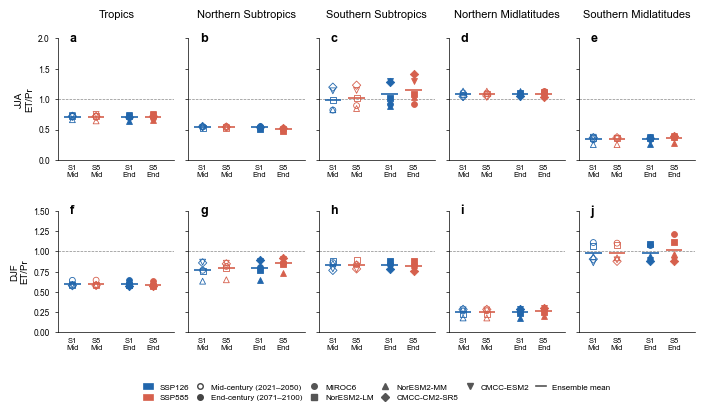

In [2]:
# Plot

import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D

# ── Nature journal style settings ────────────────────────────────────────────
matplotlib.rcParams.update({
    'font.family':       'sans-serif',
    'font.sans-serif':   ['Arial', 'Helvetica', 'DejaVu Sans'],
    'font.size':         7,
    'axes.labelsize':    7,
    'axes.titlesize':    7,
    'xtick.labelsize':   6,
    'ytick.labelsize':   6,
    'legend.fontsize':   6,
    'axes.linewidth':    0.5,
    'xtick.major.width': 0.5,
    'ytick.major.width': 0.5,
    'xtick.major.size':  2.5,
    'ytick.major.size':  2.5,
    'xtick.minor.size':  1.5,
    'ytick.minor.size':  1.5,
    'lines.linewidth':   1.0,
    'pdf.fonttype':      42,
    'svg.fonttype':      'none',
})

# ── Load data from Excel ──────────────────────────────────────────────────────
excel_file = "/Users/dianindrawati/Documents/Python/CMIP6_and_ERA5/P_over_E/E_over_P_recap_rev1.xlsx"

df_jja = pd.read_excel(excel_file, sheet_name='JJA')
df_djf = pd.read_excel(excel_file, sheet_name='DJF')

# Forward-fill Model, Period, Scenario columns (merged cells in Excel)
for df in [df_jja, df_djf]:
    df[['Model', 'Period', 'Scenario']] = df[['Model', 'Period', 'Scenario']].ffill()

regions     = ['TROP', 'NSZ', 'SSZ', 'NMZ', 'SMZ']
reg_labels  = ['Tropics', 'Northern Subtropics', 'Southern Subtropics', 'Northern Midlatitudes', 'Southern Midlatitudes']
models      = ['MIROC6', 'NorESM2-LM', 'NorESM2-MM', 'CMCC-CM2-SR5', 'CMCC-ESM2']
scenarios   = ['SSP126', 'SSP585']
periods     = ['2021-2050', '2071-2100']


def row_ylim(df, regions, pad_frac=0.12):
    vals = df[regions].values.astype(float)
    vmin, vmax = np.nanmin(vals), np.nanmax(vals)
    span = vmax - vmin
    return vmin - span*pad_frac, vmax + span*pad_frac

# ── Row-wise y-axis limits (manually defined) ────────────────────────────────
ylim_jja = (0.0, 2.0)   # adjust to whatever bounds you want for the JJA row
ylim_djf = (0.0, 1.5)   # adjust to whatever bounds you want for the DJF row

#ylim_jja = row_ylim(df_jja, regions)
#ylim_djf = row_ylim(df_djf, regions)

# ── Colours & markers ─────────────────────────────────────────────────────────
# SSP: blue family (126) and red family (585)
ssp_colors  = {'SSP126': '#2166ac', 'SSP585': '#d6604d'}
period_fill = {'2021-2050': 'none', '2071-2100': None}   # open = near, filled = far
model_markers = {
    'MIROC6':       'o',
    'NorESM2-LM':   's',
    'NorESM2-MM':   '^',
    'CMCC-CM2-SR5': 'D',
    'CMCC-ESM2':    'v',
}
marker_size = 18   # in scatter units

# ── Build figure: 2 rows (JJA / DJF) × 5 columns (regions) ──────────────────
# Nature single-column = 88 mm ≈ 3.46 in; double-column = 180 mm ≈ 7.08 in
fig_w = 7.08   # inches (Nature double-column)
fig_h = 4.2    # inches
fig, axes = plt.subplots(2, 5, figsize=(fig_w, fig_h),
                         sharey='row', sharex=False)
fig.subplots_adjust(wspace=0.12, hspace=0.42,
                    left=0.07, right=0.97, top=0.88, bottom=0.18)

def plot_panel(ax, df, region):
    """Scatter individual model values; overlay ensemble mean bar."""
    x_pos = 0
    xticks, xlabels = [], []

    for per in periods:
        for ssp in scenarios:
            sub = df[(df['Scenario'] == ssp) & (df['Period'] == per)]
            vals = sub[region].values
            col  = ssp_colors[ssp]
            fill = period_fill[per]

            # ensemble mean marker (horizontal line)
            ax.hlines(np.mean(vals), x_pos - 0.35, x_pos + 0.35,
                      color=col, linewidth=1.2, zorder=3)

            for i, (model, v) in enumerate(zip(sub['Model'].values, vals)):
                mkr = model_markers[model]
                fc  = col if fill is None else 'none'
                ax.scatter(x_pos, v, marker=mkr, s=marker_size,
                           facecolor=fc, edgecolor=col,
                           linewidth=0.6, zorder=4, clip_on=False)

            xticks.append(x_pos)
            xlabels.append(f"{'S1' if ssp == 'SSP126' else 'S5'}\n{'Mid' if per == '2021-2050' else 'End'}")
            x_pos += 1

        # small gap between Mid and End groups
        x_pos += 0.4

    # E/P = 1 reference line
    ax.axhline(1.0, color='#888888', linewidth=0.5, linestyle='--', zorder=1)

    ax.set_xticks(xticks)
    ax.set_xticklabels(xlabels, fontsize=5.5)
    ax.tick_params(axis='x', length=0)
    ax.set_xlim(-0.6, x_pos - 0.5)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)


# ── Populate panels ───────────────────────────────────────────────────────────
season_dfs  = [df_jja, df_djf]
season_lbls = ['JJA', 'DJF']
panel_labels = list('abcdefghij')

for row, (df, slbl) in enumerate(zip(season_dfs, season_lbls)):
    ylim = ylim_jja if row == 0 else ylim_djf 
    for col, (reg, rlbl) in enumerate(zip(regions, reg_labels)):
        ax = axes[row, col]
        plot_panel(ax, df, reg)
        ax.set_ylim(*ylim)   # <-- explicit, generous headroom


        # panel letter
        ax.text(0.1, 1.05, panel_labels[row * 5 + col],
                transform=ax.transAxes, fontsize=9,
                fontweight='bold', va='top', ha='left')

        if row == 0:
            ax.set_title(rlbl, fontsize=8, pad=15)
        if col == 0:
            ax.set_ylabel(f'{slbl}\nET/Pr', fontsize=7, labelpad=3)

# ── Legend ────────────────────────────────────────────────────────────────────
legend_elements = []

# SSP colour patches
for ssp, col in ssp_colors.items():
    legend_elements.append(
        mpatches.Patch(facecolor=col, edgecolor=col, label=ssp, linewidth=0.5))

# period (open = near future, filled = far future) — use a circle as example
legend_elements.append(
    Line2D([0], [0], marker='o', color='none', markerfacecolor='none',
           markeredgecolor='#444444', markersize=4, label='Mid-century (2021–2050)', linewidth=0))
legend_elements.append(
    Line2D([0], [0], marker='o', color='none', markerfacecolor='#444444',
           markeredgecolor='#444444', markersize=4, label='End-century (2071–2100)', linewidth=0))

# model markers
for model, mkr in model_markers.items():
    legend_elements.append(
        Line2D([0], [0], marker=mkr, color='none', markerfacecolor='#555555',
               markeredgecolor='#555555', markersize=4, label=model, linewidth=0))

# ensemble mean line
legend_elements.append(
    Line2D([0], [0], color='#555555', linewidth=1.2, label='Ensemble mean'))

fig.legend(handles=legend_elements, loc='lower center',
           ncol=6, frameon=False, fontsize=5.8,
           bbox_to_anchor=(0.52, 0.0), columnspacing=0.8, handlelength=1.2)

# ── Save ──────────────────────────────────────────────────────────────────────
out_png = '/Users/dianindrawati/Documents/Python/CMIP6_and_ERA5/P_over_E/EP_ratio_Nature.png'
fig.savefig(out_png, dpi=800, bbox_inches='tight')
print("Saved:", out_png)